In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Load the CSV dataset
df = pd.read_csv(
    "student_sleep_screen_time_academic_performance.csv"
)

# Explore the dataset
print("Dataset dimensions:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe())


Dataset dimensions: (500, 25)

First five rows:


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    str    
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    str    
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    str    
 5   residence_type             500 non-null    str    
 6   chronotype                 500 non-null    str    
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    str    
 13  device_free_before_bed     491 non-null 

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000


In [3]:

# Select nine meaningful input features
features = [
    "age",
    "avg_sleep_hours_weekday",
    "daily_screen_time_hours",
    "pre_sleep_screen_time_min",
    "caffeine_drinks_per_day",
    "sleep_quality_score",
    "exercise_days_per_week",
    "weekly_study_hours",
    "class_attendance_percent"
]

# CGPA must be known for supervised training
model_data = df.dropna(subset=["cgpa"]).copy()

# Input features
X = model_data[features]

# Regression target: numerical CGPA
y_regression = model_data["cgpa"]

# Classification target derived from CGPA
# 0 = below 3.0
# 1 = CGPA of 3.0 or above
y_classification = (
    model_data["cgpa"] >= 3.0
).astype(int)

print("Records available:", len(model_data))
print("\nSelected input features:")
print(features)

print("\nClassification category counts:")
print(
    y_classification.map({
        0: "Below 3.0",
        1: "CGPA 3.0 or above"
    }).value_counts()
)

print("\nMissing values in selected features:")
print(X.isnull().sum())


Records available: 493

Selected input features:
['age', 'avg_sleep_hours_weekday', 'daily_screen_time_hours', 'pre_sleep_screen_time_min', 'caffeine_drinks_per_day', 'sleep_quality_score', 'exercise_days_per_week', 'weekly_study_hours', 'class_attendance_percent']

Classification category counts:
cgpa
Below 3.0            346
CGPA 3.0 or above    147
Name: count, dtype: int64

Missing values in selected features:
age                          0
avg_sleep_hours_weekday      0
daily_screen_time_hours      0
pre_sleep_screen_time_min    0
caffeine_drinks_per_day      0
sleep_quality_score          6
exercise_days_per_week       0
weekly_study_hours           0
class_attendance_percent     0
dtype: int64


LINEAR REGRESSION RESULTS
-------------------------
R-squared (R2): 0.3452
Mean Absolute Error: 0.2089
Root Mean Squared Error: 0.2588


,Actual CGPA,Predicted CGPA
0,2.44,2.738353
1,2.47,2.658471
2,2.62,2.988042
3,2.15,2.560112
4,2.97,2.923099
5,2.20,2.481863
6,2.75,2.820577
7,2.99,2.830502
8,3.08,2.704257
9,3.13,3.098115


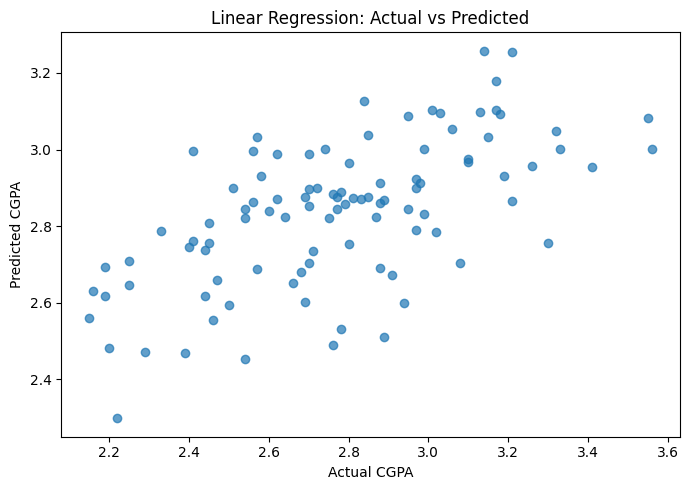

In [4]:

# Split into 80% training data and 20% testing data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
    train_test_split(
        X,
        y_regression,
        test_size=0.20,
        random_state=42
    )
)

# Create the regression pipeline
regression_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train the model
regression_model.fit(X_train_reg, y_train_reg)

# Predict CGPA for the test set
y_pred_reg = regression_model.predict(X_test_reg)

# Evaluate regression performance
reg_r2 = r2_score(y_test_reg, y_pred_reg)
reg_mae = mean_absolute_error(y_test_reg, y_pred_reg)
reg_rmse = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_reg)
)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print(f"R-squared (R2): {reg_r2:.4f}")
print(f"Mean Absolute Error: {reg_mae:.4f}")
print(f"Root Mean Squared Error: {reg_rmse:.4f}")

# Compare actual and predicted values
regression_results = pd.DataFrame({
    "Actual CGPA": y_test_reg.to_numpy(),
    "Predicted CGPA": y_pred_reg
})

display(regression_results.head(10))

# Plot actual versus predicted CGPA
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.7)

plt.xlabel("Actual CGPA")
plt.ylabel("Predicted CGPA")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()


LOGISTIC REGRESSION CLASSIFICATION RESULTS
------------------------------------------
Accuracy:  0.7475
Precision: 0.6471
Recall:    0.3667
F1-score:  0.4681

Classification report:
                   precision    recall  f1-score   support

        Below 3.0       0.77      0.91      0.83        69
CGPA 3.0 or above       0.65      0.37      0.47        30

         accuracy                           0.75        99
        macro avg       0.71      0.64      0.65        99
     weighted avg       0.73      0.75      0.72        99



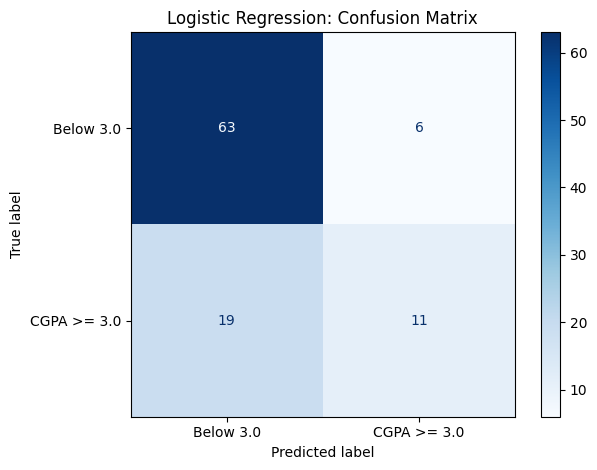

In [5]:

# Split the data, keeping the class proportions similar
X_train_clf, X_test_clf, y_train_clf, y_test_clf = (
    train_test_split(
        X,
        y_classification,
        test_size=0.20,
        random_state=42,
        stratify=y_classification
    )
)

# Create the classification pipeline
classification_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

# Train the classifier
classification_model.fit(X_train_clf, y_train_clf)

# Predict categories for the test set
y_pred_clf = classification_model.predict(X_test_clf)

# Evaluate classification performance
clf_accuracy = accuracy_score(y_test_clf, y_pred_clf)

clf_precision = precision_score(
    y_test_clf, y_pred_clf, zero_division=0
)

clf_recall = recall_score(
    y_test_clf, y_pred_clf, zero_division=0
)

clf_f1 = f1_score(
    y_test_clf, y_pred_clf, zero_division=0
)

print("LOGISTIC REGRESSION CLASSIFICATION RESULTS")
print("------------------------------------------")
print(f"Accuracy:  {clf_accuracy:.4f}")
print(f"Precision: {clf_precision:.4f}")
print(f"Recall:    {clf_recall:.4f}")
print(f"F1-score:  {clf_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test_clf,
        y_pred_clf,
        labels=[0, 1],
        target_names=["Below 3.0", "CGPA 3.0 or above"],
        zero_division=0
    )
)

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_clf,
    y_pred_clf,
    labels=[0, 1],
    display_labels=["Below 3.0", "CGPA >= 3.0"],
    cmap="Blues"
)

plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()


In [6]:

# Save both trained pipelines
joblib.dump(regression_model, "regression_model.joblib")
joblib.dump(classification_model, "classification_model.joblib")

# Save metrics so the web page can display the actual results
metrics = {
    "dataset": "Student Sleep, Screen Time & Academic Performance",
    "records_in_dataset": int(len(df)),
    "records_with_known_cgpa": int(len(model_data)),
    "regression": {
        "algorithm": "Linear Regression",
        "r2": float(reg_r2),
        "mae": float(reg_mae),
        "rmse": float(reg_rmse)
    },
    "classification": {
        "algorithm": "Logistic Regression",
        "accuracy": float(clf_accuracy),
        "precision": float(clf_precision),
        "recall": float(clf_recall),
        "f1_score": float(clf_f1)
    },
    "classification_threshold": 3.0,
    "features": features
}

with open("metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print("Both models and evaluation results saved successfully.")
print("Created: regression_model.joblib")
print("Created: classification_model.joblib")
print("Created: metrics.json")


Both models and evaluation results saved successfully.
Created: regression_model.joblib
Created: classification_model.joblib
Created: metrics.json
